# Lab 05: HOG-Based Industrial Defect Detection and Classification

Pipeline: Image -> Preprocessing (resize, grayscale) -> HOG features -> Classifier -> Decision

NEU-DET only contains defective steel surfaces (6 defect types: crazing, inclusion, patches, pitted_surface, rolled-in_scale, scratches), so this notebook does the multi-class version. Any predicted defect type means REJECT. If you have normal (defect-free) images, put them in `/content/normal/` before running and they are added as an extra class called `normal`, which enables the ACCEPT decision.

Run all cells top to bottom (CPU is enough).

In [1]:
!pip install -q kagglehub

In [2]:
import os, re, glob, time, warnings
import numpy as np
import pandas as pd
import cv2
import joblib
import matplotlib.pyplot as plt
import seaborn as sns
from skimage.feature import hog
from skimage import exposure
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.svm import SVC, LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

warnings.filterwarnings("ignore")
np.random.seed(42)

## 1. Load and inspect the dataset

In [3]:
import subprocess, sys

SLUG = "sovitrath/neu-steel-surface-defect-detecttrainvalid-split"
DRIVE_ID = "1qrdZlaDi272eA79b0uCwwqPrm2Q_WI3k"

def get_dataset():
    try:
        import kagglehub
        return kagglehub.dataset_download(SLUG)
    except Exception as e:
        print("Kaggle download failed, trying Google Drive copy of NEU-DET instead:", str(e)[:80])
    out = "neu_det"
    if not (os.path.isdir(out) and os.listdir(out)):
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "gdown"])
        import gdown
        gdown.download(id=DRIVE_ID, output="neu_det.zip", quiet=False)
        subprocess.run(["unzip", "-q", "-o", "neu_det.zip", "-d", out])
    return out

root = get_dataset()
print("Dataset path:", root)

KNOWN = ["crazing", "inclusion", "patches", "pitted_surface", "rolled-in_scale", "scratches"]
ABBR = {"cr": "crazing", "in": "inclusion", "pa": "patches", "ps": "pitted_surface", "rs": "rolled-in_scale", "sc": "scratches"}
EXTS = (".jpg", ".jpeg", ".png", ".bmp")

def label_of(fp):
    name = os.path.basename(fp).lower()
    for c in KNOWN:
        if name.startswith(c):
            return c
    m = re.match(r"^([a-z]+)[_-]?\d+", name)
    if m and m.group(1) in ABBR:
        return ABBR[m.group(1)]
    parent = os.path.basename(os.path.dirname(fp)).lower()
    return parent if parent in KNOWN else None

def split_of(fp):
    parts = os.path.relpath(fp, root).lower().split(os.sep)
    if any(p.startswith("train") for p in parts):
        return "train"
    if any(p.startswith(("val", "test")) for p in parts):
        return "test"
    return None

records = []
for fp in glob.glob(os.path.join(root, "**", "*"), recursive=True):
    if fp.lower().endswith(EXTS):
        lab = label_of(fp)
        if lab is not None:
            records.append((fp, lab, split_of(fp)))

normal_dir = "/content/normal"
if os.path.isdir(normal_dir):
    for fp in glob.glob(os.path.join(normal_dir, "*")):
        if fp.lower().endswith(EXTS):
            records.append((fp, "normal", None))

if not records:
    sample = [f for f in glob.glob(os.path.join(root, "**", "*"), recursive=True)][:15]
    raise RuntimeError("No labelled images found. First files in the dataset folder:\n" + "\n".join(sample))

df = pd.DataFrame(records, columns=["path", "label", "split"]).drop_duplicates("path").reset_index(drop=True)

if set(df["split"].dropna()) >= {"train", "test"}:
    missing = df["split"].isna()
    if missing.any():
        a, b = train_test_split(df[missing].index, test_size=0.2, stratify=df.loc[missing, "label"], random_state=42)
        df.loc[a, "split"] = "train"
        df.loc[b, "split"] = "test"
    df = df[df["split"].notna()].reset_index(drop=True)
else:
    a, b = train_test_split(df.index, test_size=0.2, stratify=df["label"], random_state=42)
    df["split"] = "train"
    df.loc[b, "split"] = "test"

print(pd.crosstab(df["label"], df["split"]))

Kaggle download failed, trying Google Drive copy of NEU-DET instead: 403 Client Error.

You don't have permission to access resource at URL: https://


Downloading...
From (original): https://drive.google.com/uc?id=1qrdZlaDi272eA79b0uCwwqPrm2Q_WI3k
From (redirected): https://drive.google.com/uc?id=1qrdZlaDi272eA79b0uCwwqPrm2Q_WI3k&confirm=t&uuid=51119fcd-5423-4af8-9766-bddf001b636d
To: /content/neu_det.zip
100%|██████████| 27.6M/27.6M [00:00<00:00, 167MB/s]


Dataset path: neu_det
split            test  train
label                       
crazing            60    240
inclusion          60    240
patches            60    240
pitted_surface     60    240
rolled-in_scale    60    240
scratches          60    240


## 2-3. Resize and convert to grayscale

classes: ['crazing', 'inclusion', 'patches', 'pitted_surface', 'rolled-in_scale', 'scratches']
train: (1440, 128, 128) test: (360, 128, 128)


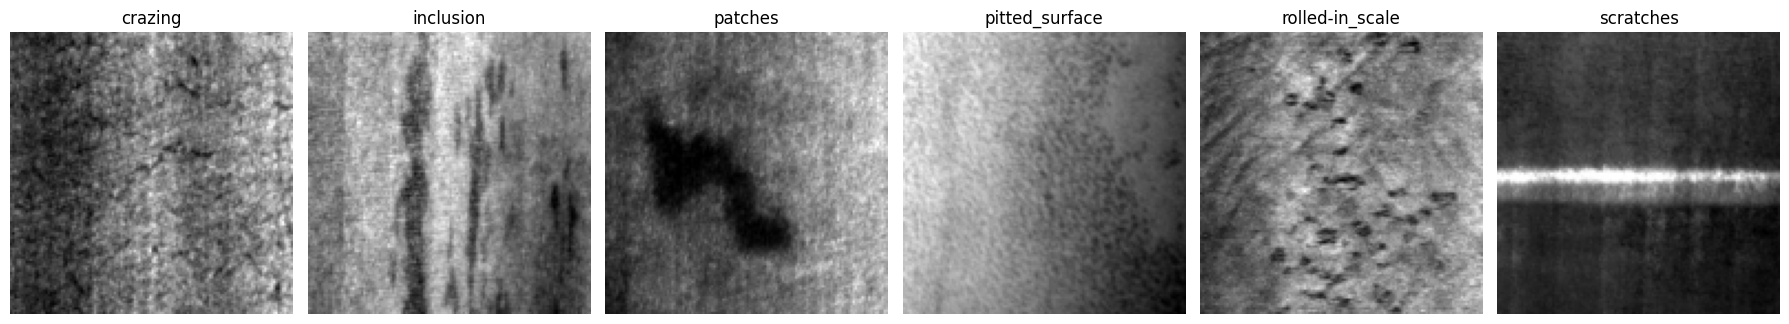

In [4]:
IMG = 128

def load_gray(fp):
    im = cv2.imread(fp, cv2.IMREAD_GRAYSCALE)
    if im is None:
        return None
    return cv2.resize(im, (IMG, IMG), interpolation=cv2.INTER_AREA)

imgs, keep = [], []
for i, fp in enumerate(df["path"]):
    im = load_gray(fp)
    if im is not None:
        imgs.append(im)
        keep.append(i)

df = df.iloc[keep].reset_index(drop=True)
X = np.stack(imgs)
le = LabelEncoder()
y = le.fit_transform(df["label"])
classes = list(le.classes_)

is_train = (df["split"] == "train").values
X_train, y_train = X[is_train], y[is_train]
X_test, y_test = X[~is_train], y[~is_train]
print("classes:", classes)
print("train:", X_train.shape, "test:", X_test.shape)

fig, axes = plt.subplots(1, len(classes), figsize=(3 * len(classes), 3.3))
for j, c in enumerate(classes):
    axes[j].imshow(X_train[y_train == j][0], cmap="gray")
    axes[j].set_title(c)
    axes[j].axis("off")
plt.tight_layout()
plt.show()

## 4-5. HOG features and visualization

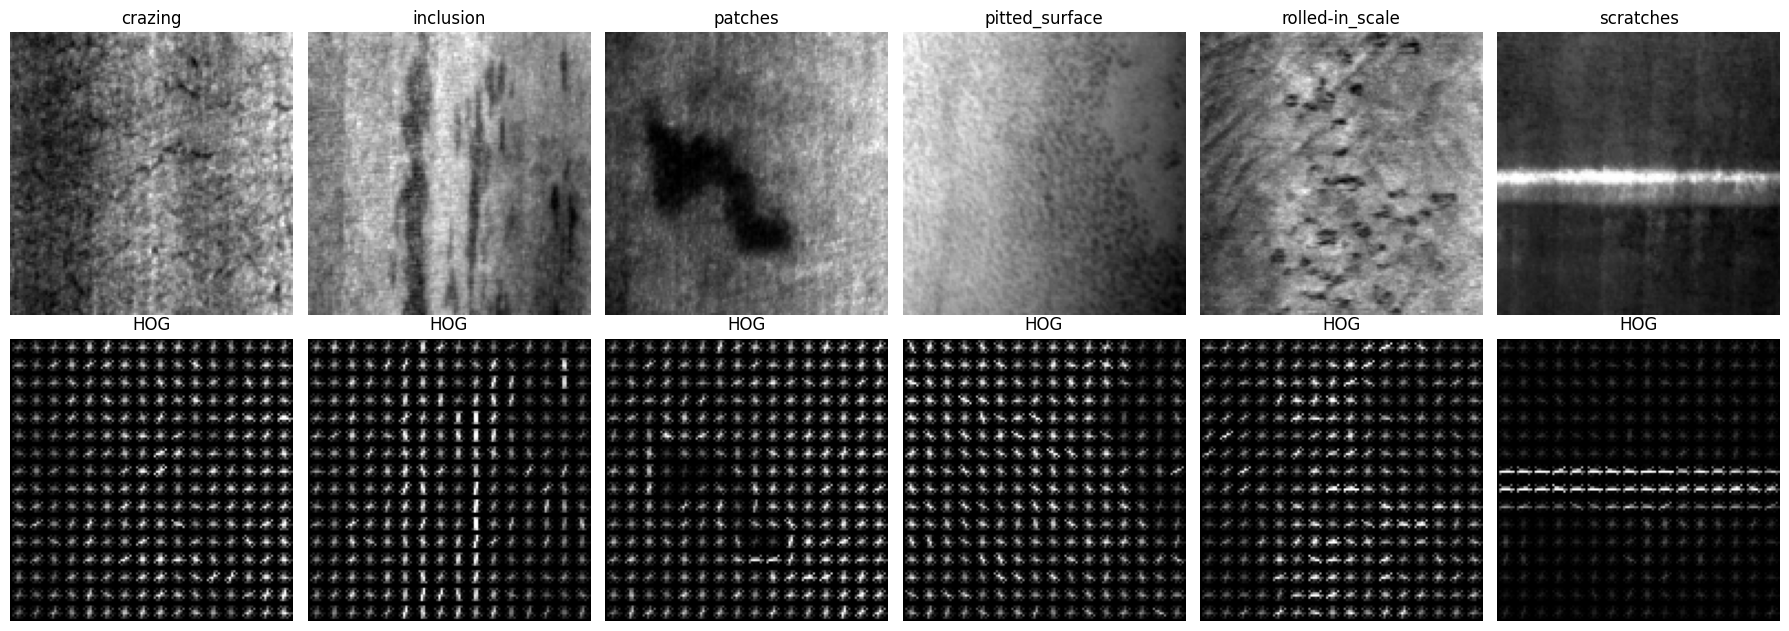

In [5]:
def hog_one(im, cell=8, ori=9):
    return hog(im, orientations=ori, pixels_per_cell=(cell, cell), cells_per_block=(2, 2),
               block_norm="L2-Hys", feature_vector=True)

def hog_batch(images, cell=8, ori=9):
    return np.array([hog_one(im, cell, ori) for im in images], dtype=np.float32)

fig, axes = plt.subplots(2, len(classes), figsize=(3 * len(classes), 6.4))
for j, c in enumerate(classes):
    im = X_train[y_train == j][0]
    _, hog_img = hog(im, orientations=9, pixels_per_cell=(8, 8), cells_per_block=(2, 2),
                     block_norm="L2-Hys", visualize=True)
    hog_img = exposure.rescale_intensity(hog_img, in_range=(0, np.percentile(hog_img, 99.5) + 1e-6))
    axes[0, j].imshow(im, cmap="gray"); axes[0, j].set_title(c); axes[0, j].axis("off")
    axes[1, j].imshow(hog_img, cmap="gray"); axes[1, j].set_title("HOG"); axes[1, j].axis("off")
plt.tight_layout()
plt.show()

## 11. HOG parameter study (cell size x orientations)

To avoid choosing parameters on the test data, 20% of the training set is held out as a validation set here. The official test split is only used later.

In [6]:
idx_fit, idx_val = train_test_split(np.arange(len(y_train)), test_size=0.2, stratify=y_train, random_state=42)

sweep = []
for cell in (4, 8, 16):
    for ori in (6, 9, 12):
        t0 = time.time()
        F = hog_batch(X_train, cell, ori)
        clf = LinearSVC(C=1.0, dual=True, max_iter=5000, random_state=42).fit(F[idx_fit], y_train[idx_fit])
        pred = clf.predict(F[idx_val])
        sweep.append({
            "Cell": cell, "Orientations": ori, "Features": F.shape[1],
            "Accuracy (%)": round(100 * accuracy_score(y_train[idx_val], pred), 2),
            "F1 (%)": round(100 * f1_score(y_train[idx_val], pred, average="macro"), 2),
            "Time (s)": round(time.time() - t0, 1),
        })
        print(cell, ori, sweep[-1]["Accuracy (%)"])

sweep_df = pd.DataFrame(sweep)
sweep_df.to_csv("hog_parameter_study.csv", index=False)
sweep_df

4 6 59.72
4 9 63.89
4 12 72.57
8 6 67.01
8 9 70.14
8 12 75.69
16 6 77.08
16 9 73.96
16 12 76.04


,Cell,Orientations,Features,Accuracy (%),F1 (%),Time (s)
0,4,6,23064,59.72,59.07,62.0
1,4,9,34596,63.89,63.53,59.9
2,4,12,46128,72.57,72.30,56.3
3,8,6,5400,67.01,66.38,36.3
4,8,9,8100,70.14,69.59,30.6
5,8,12,10800,75.69,75.19,27.3
6,16,6,1176,77.08,76.88,13.5
7,16,9,1764,73.96,73.60,17.1
8,16,12,2352,76.04,75.88,16.9


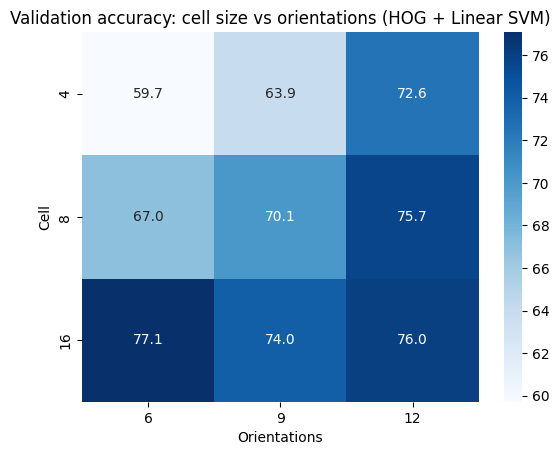

Best HOG setting: cell 16 x 16 | orientations 6


In [7]:
pivot = sweep_df.pivot(index="Cell", columns="Orientations", values="Accuracy (%)")
sns.heatmap(pivot, annot=True, fmt=".1f", cmap="Blues")
plt.title("Validation accuracy: cell size vs orientations (HOG + Linear SVM)")
plt.show()

best = sweep_df.sort_values(["F1 (%)", "Accuracy (%)", "Features"], ascending=[False, False, True]).iloc[0]
BEST_CELL, BEST_ORI = int(best["Cell"]), int(best["Orientations"])
print("Best HOG setting: cell", BEST_CELL, "x", BEST_CELL, "| orientations", BEST_ORI)

## 6-10. SVM and other classifiers on the official test split

In [8]:
F_train = hog_batch(X_train, BEST_CELL, BEST_ORI)
F_test = hog_batch(X_test, BEST_CELL, BEST_ORI)

c_rows = []
for C in (1, 10, 100):
    m = SVC(kernel="rbf", C=C, gamma="scale").fit(F_train[idx_fit], y_train[idx_fit])
    p = m.predict(F_train[idx_val])
    c_rows.append((C, f1_score(y_train[idx_val], p, average="macro")))
BEST_C = max(c_rows, key=lambda r: r[1])[0]
print("SVM C values (validation F1):", [(c, round(f, 3)) for c, f in c_rows], "-> using C =", BEST_C)

SVM C values (validation F1): [(1, 0.923), (10, 0.92), (100, 0.913)] -> using C = 1


In [9]:
models = {
    "SVM (RBF)": SVC(kernel="rbf", C=BEST_C, gamma="scale", probability=True, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=42),
    "KNN (k=5)": KNeighborsClassifier(n_neighbors=5),
}

rows, preds = [], {}
for name, model in models.items():
    t0 = time.time()
    model.fit(F_train, y_train)
    train_time = time.time() - t0
    t0 = time.time()
    p = model.predict(F_test)
    infer_ms = (time.time() - t0) / len(F_test) * 1000
    preds[name] = p
    rows.append({
        "Classifier": name,
        "Accuracy (%)": round(100 * accuracy_score(y_test, p), 2),
        "Precision (%)": round(100 * precision_score(y_test, p, average="macro", zero_division=0), 2),
        "Recall (%)": round(100 * recall_score(y_test, p, average="macro", zero_division=0), 2),
        "F1-Score (%)": round(100 * f1_score(y_test, p, average="macro", zero_division=0), 2),
        "Train time (s)": round(train_time, 1),
        "Inference (ms/image)": round(infer_ms, 3),
    })

results_df = pd.DataFrame(rows)
results_df.to_csv("classifier_comparison.csv", index=False)
results_df

,Classifier,Accuracy (%),Precision (%),Recall (%),F1-Score (%),Train time (s),Inference (ms/image)
0,SVM (RBF),92.50,92.60,92.50,92.46,4.7,2.644
1,Random Forest,90.00,90.24,90.00,89.94,17.2,0.273
2,KNN (k=5),70.28,77.94,70.28,67.17,0.0,0.347


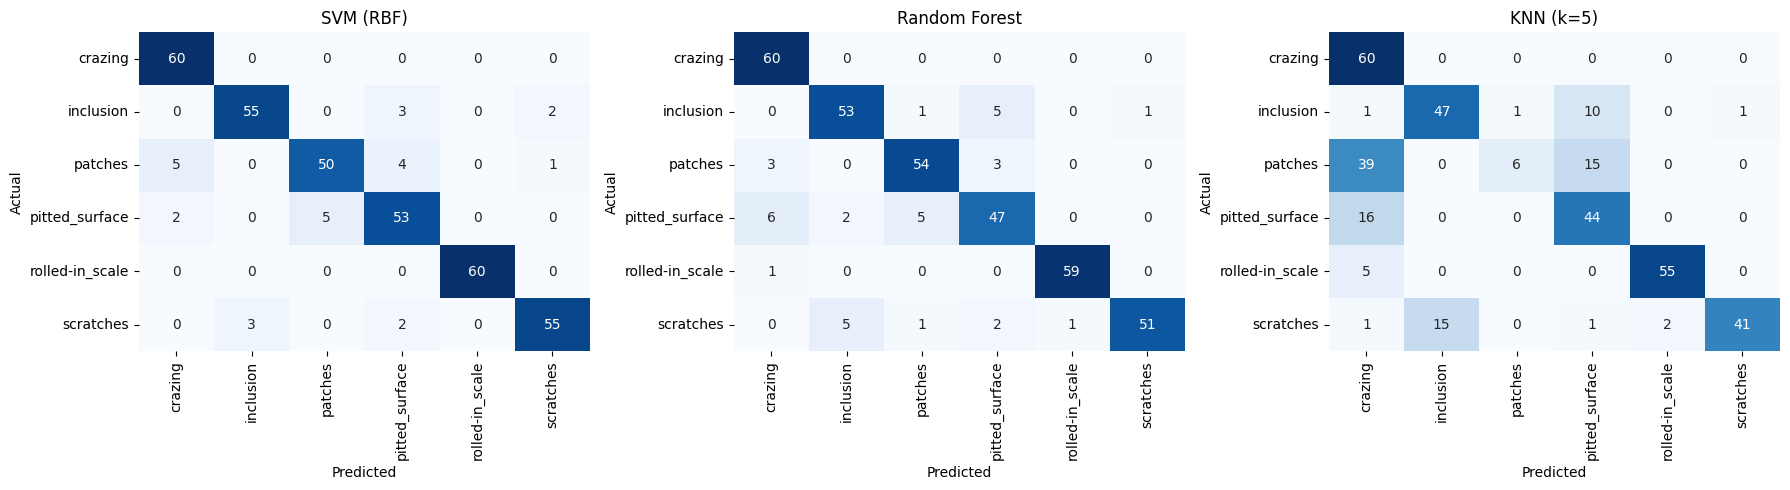

===== SVM (RBF) =====
                 precision    recall  f1-score   support

        crazing      0.896     1.000     0.945        60
      inclusion      0.948     0.917     0.932        60
        patches      0.909     0.833     0.870        60
 pitted_surface      0.855     0.883     0.869        60
rolled-in_scale      1.000     1.000     1.000        60
      scratches      0.948     0.917     0.932        60

       accuracy                          0.925       360
      macro avg      0.926     0.925     0.925       360
   weighted avg      0.926     0.925     0.925       360

===== Random Forest =====
                 precision    recall  f1-score   support

        crazing      0.857     1.000     0.923        60
      inclusion      0.883     0.883     0.883        60
        patches      0.885     0.900     0.893        60
 pitted_surface      0.825     0.783     0.803        60
rolled-in_scale      0.983     0.983     0.983        60
      scratches      0.981     0.850

In [10]:
fig, axes = plt.subplots(1, len(models), figsize=(6 * len(models), 5))
for ax, (name, p) in zip(np.atleast_1d(axes), preds.items()):
    sns.heatmap(confusion_matrix(y_test, p), annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=classes, yticklabels=classes, ax=ax)
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
plt.tight_layout()
plt.show()

for name, p in preds.items():
    print("=====", name, "=====")
    print(classification_report(y_test, p, target_names=classes, digits=3, zero_division=0))

In [11]:
final_svm = models["SVM (RBF)"]
joblib.dump({"model": final_svm, "cell": BEST_CELL, "orientations": BEST_ORI, "classes": classes, "img": IMG}, "hog_svm_model.joblib")
print("saved hog_svm_model.joblib")

saved hog_svm_model.joblib


## 12. Robustness test (the trained SVM is not retrained)

In [12]:
def brightness(im, i, f):
    return np.clip(im.astype(np.float32) * f, 0, 255).astype(np.uint8)

def gauss_noise(im, i, sigma):
    noise = np.random.default_rng(i).normal(0, sigma, im.shape)
    return np.clip(im.astype(np.float32) + noise, 0, 255).astype(np.uint8)

def rotate(im, i, angle):
    M = cv2.getRotationMatrix2D((IMG / 2, IMG / 2), angle, 1.0)
    return cv2.warpAffine(im, M, (IMG, IMG), borderMode=cv2.BORDER_REFLECT)

def blur(im, i, k):
    return cv2.GaussianBlur(im, (k, k), 0)

conditions = [
    ("Clean", lambda im, i: im),
    ("Brightness x0.6", lambda im, i: brightness(im, i, 0.6)),
    ("Brightness x1.4", lambda im, i: brightness(im, i, 1.4)),
    ("Gaussian noise sigma=10", lambda im, i: gauss_noise(im, i, 10)),
    ("Gaussian noise sigma=25", lambda im, i: gauss_noise(im, i, 25)),
    ("Rotation 10 deg", lambda im, i: rotate(im, i, 10)),
    ("Rotation 30 deg", lambda im, i: rotate(im, i, 30)),
    ("Blur 3x3", lambda im, i: blur(im, i, 3)),
    ("Blur 7x7", lambda im, i: blur(im, i, 7)),
]

rob_rows = []
for name, fn in conditions:
    Xp = [fn(im, i) for i, im in enumerate(X_test)]
    p = final_svm.predict(hog_batch(Xp, BEST_CELL, BEST_ORI))
    rob_rows.append({
        "Condition": name,
        "Accuracy (%)": round(100 * accuracy_score(y_test, p), 2),
        "F1 (%)": round(100 * f1_score(y_test, p, average="macro", zero_division=0), 2),
    })

rob_df = pd.DataFrame(rob_rows)
rob_df["Accuracy change"] = (rob_df["Accuracy (%)"] - rob_df.loc[0, "Accuracy (%)"]).round(2)
rob_df["F1 change"] = (rob_df["F1 (%)"] - rob_df.loc[0, "F1 (%)"]).round(2)
rob_df.to_csv("robustness_results.csv", index=False)
rob_df

,Condition,Accuracy (%),F1 (%),Accuracy change,F1 change
0,Clean,92.50,92.46,0.00,0.00
1,Brightness x0.6,91.11,90.97,-1.39,-1.49
2,Brightness x1.4,67.78,67.66,-24.72,-24.80
3,Gaussian noise sigma=10,24.44,17.27,-68.06,-75.19
4,Gaussian noise sigma=25,18.61,8.23,-73.89,-84.23
5,Rotation 10 deg,91.39,91.45,-1.11,-1.01
6,Rotation 30 deg,75.83,75.76,-16.67,-16.70
7,Blur 3x3,77.22,76.80,-15.28,-15.66
8,Blur 7x7,19.44,10.84,-73.06,-81.62


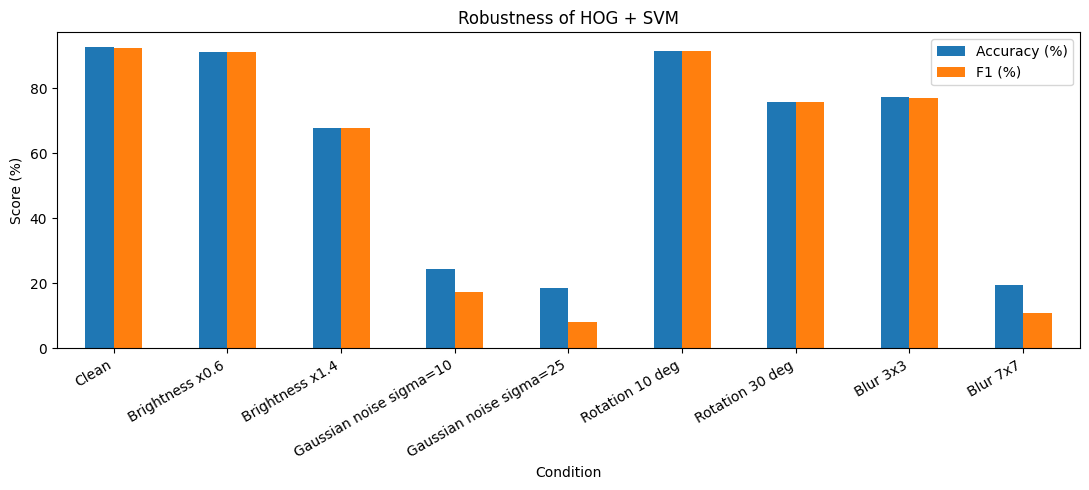

In [13]:
rob_df.set_index("Condition")[["Accuracy (%)", "F1 (%)"]].plot(kind="bar", figsize=(11, 5))
plt.ylabel("Score (%)")
plt.title("Robustness of HOG + SVM")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

## 13. Quality-control decision module

In [14]:
CONF_THRESHOLD = 60.0

def inspect_product(image, show=True):
    if isinstance(image, str):
        image = cv2.imread(image, cv2.IMREAD_GRAYSCALE)
    elif image.ndim == 3:
        image = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    image = cv2.resize(image, (IMG, IMG), interpolation=cv2.INTER_AREA)

    feat = hog_one(image, BEST_CELL, BEST_ORI).reshape(1, -1)
    k = int(final_svm.predict(feat)[0])
    conf = 100 * final_svm.predict_proba(feat)[0][list(final_svm.classes_).index(k)]
    label = classes[k]

    if label == "normal":
        prediction, action = "NON-DEFECTIVE", "ACCEPT PRODUCT"
    else:
        prediction, action = "DEFECTIVE", "REJECT PRODUCT"

    if show:
        print("PRODUCT INSPECTION RESULT")
        print("Prediction:", prediction)
        if label != "normal":
            print("Defect type:", label)
        print("Confidence: %.0f%%" % conf)
        print("Action:", action)
        if conf < CONF_THRESHOLD:
            print("Note: low confidence, send for manual check")
    return {"label": label, "prediction": prediction, "action": action, "confidence": conf}

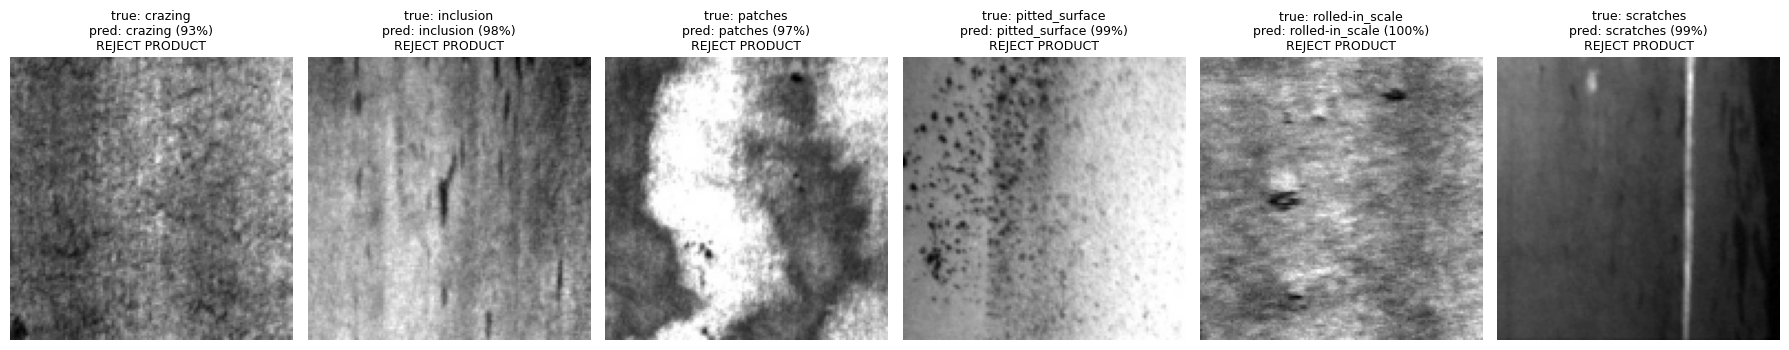

Example (true class: crazing)

PRODUCT INSPECTION RESULT
Prediction: DEFECTIVE
Defect type: crazing
Confidence: 97%
Action: REJECT PRODUCT


{'label': 'crazing',
 'prediction': 'DEFECTIVE',
 'action': 'REJECT PRODUCT',
 'confidence': np.float64(97.23511684773982)}

In [15]:
rng = np.random.default_rng(1)
fig, axes = plt.subplots(1, len(classes), figsize=(3 * len(classes), 3.6))
for j, c in enumerate(classes):
    i = rng.choice(np.where(y_test == j)[0])
    res = inspect_product(X_test[i], show=False)
    axes[j].imshow(X_test[i], cmap="gray")
    axes[j].set_title("true: %s\npred: %s (%.0f%%)\n%s" % (c, res["label"], res["confidence"], res["action"]), fontsize=9)
    axes[j].axis("off")
plt.tight_layout()
plt.show()

i = rng.integers(len(X_test))
print("Example (true class: %s)\n" % classes[y_test[i]])
inspect_product(X_test[i])

## Bonus: video-stream prototype

Processed 60 frames, 141.9 frames per second


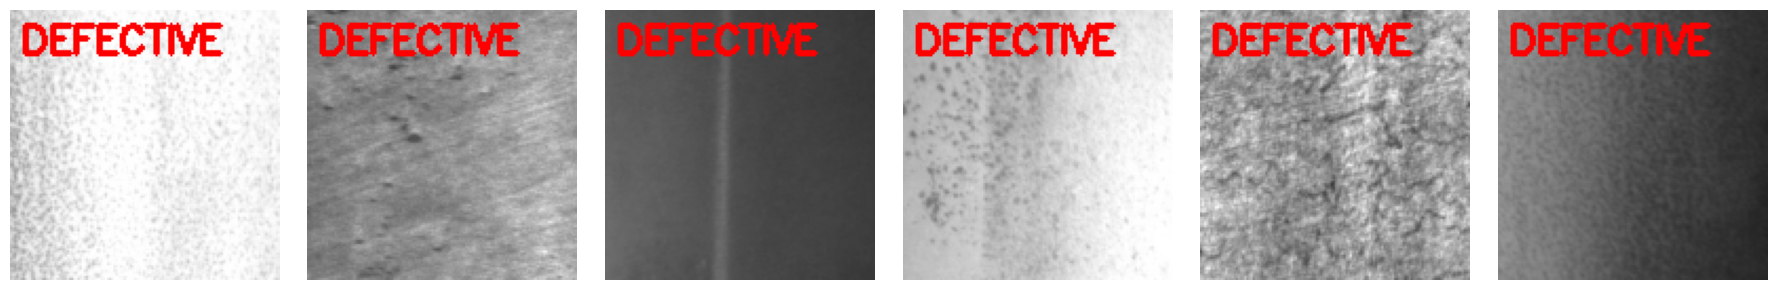

In [16]:
order = np.random.default_rng(2).permutation(len(X_test))[:60]
shown = []
t0 = time.time()
for i in order:
    res = inspect_product(X_test[i], show=False)
    status = "PASS" if res["prediction"] == "NON-DEFECTIVE" else "DEFECTIVE"
    frame = cv2.cvtColor(X_test[i], cv2.COLOR_GRAY2BGR)
    color = (0, 200, 0) if status == "PASS" else (0, 0, 255)
    cv2.putText(frame, status, (5, 20), cv2.FONT_HERSHEY_SIMPLEX, 0.6, color, 2)
    if len(shown) < 6:
        shown.append(frame)
fps = len(order) / (time.time() - t0)
print("Processed %d frames, %.1f frames per second" % (len(order), fps))

fig, axes = plt.subplots(1, len(shown), figsize=(3 * len(shown), 3))
for ax, fr in zip(axes, shown):
    ax.imshow(cv2.cvtColor(fr, cv2.COLOR_BGR2RGB))
    ax.axis("off")
plt.tight_layout()
plt.show()